# GVH Diagonal Cubic — CHH-03
## `GVH_CHH_03_Internal_Dynamics_and_Frequency_FAST`
### Hétérogénéité des dynamiques, signatures fréquentielles et pertes à l'agrégation

**Statut :** audit numérique *complémentaire*, non canonique, inspiré par la Composition hétérodynamique hiérarchique (CHH). Ce notebook ne remplace ni CHH-01, ni CHH-02, ni la branche de l'action candidate `S_cand`.

**Question falsifiable locale :** les trois sous-cubes de mécanismes différents présentent-ils des fréquences internes identifiables sur une même horloge ? Les mêmes fréquences sont-elles visibles (i) dans leur état détaillé, (ii) dans une observable effective normalisée, (iii) dans le monopôle de masse ? Une fréquence de somme/différence peut-elle apparaître du seul fait de l'observable non linéaire, sans couplage des équations de mouvement ?

**Quatre niveaux obligatoires :**
1. **GVH :** les notions de cubes hétérogènes et d'agrégation sont une proposition de modélisation, **non dérivée** de `S_cand`.
2. **Physique établie :** mécanique harmonique, oscillateur amorti, équation de continuité sur un réseau, FFT, identité trigonométrique des bandes latérales.
3. **Test minimal :** EOM classiques intégrées; comparaison aux solutions de référence; diagnostics de conservation, de dissipation, d'échantillonnage et de spectre.
4. **Verdict scientifique :** succès de QA local uniquement; aucun paramètre GVH dérivé, aucune fréquence astrophysique prédite, aucune comparaison ALMA ni micro/macro validée.

**Horloge unique :** `t` est en secondes, `dt=0.125 s`, `T=512 s`, sans changement d'échelle temporelle entre sous-cubes. Les trois fréquences sont choisies **avant** les mesures dans ce banc synthétique; elles ne résultent pas de l'action GVH. Les masses sont fictives et servent au bilan comptable seulement.

## Architecture testée

**Sous-cube A (oscillation mécanique conservatrice, 200 kg de masse d'inventaire)** : déplacement `x_A` répondant à `ẍ_A + ω_A² x_A = 0`, avec `f_A=13/512 Hz`. On normalise par une longueur de référence `L_A=1 m`.

**Sous-cube B (circulation interne forcée, 300 kg)** : trois réservoirs, circulant à travers trois liens orientés d'un anneau. Chaque flux positif est `J_e(t)=J_0[1+α sin(2π f_B t+φ)]`; `f_B=29/512 Hz`. Le courant suit la loi de continuité `ṁ=B J`; les masses demeurent constantes puisque `B(1,1,1)^T=0`. **La fréquence B est prescrite : le mécanisme source du pompage et son bilan énergétique ne sont PAS modélisés.**

**Sous-cube C (oscillation amortie, 500 kg de masse d'inventaire)** : déplacement `x_C` répondant à `ẍ_C+2γẋ_C+ω_{0,C}²x_C=0`, avec `ω_{0,C}²=(2πf_C)²+γ²`, `f_C=47/512 Hz`. Le mouvement amorti exact est `e^{-γt}cos(2πf_Ct)` pour les conditions initiales choisies. Pour ce secteur mécanique uniquement, le bilan d'énergie satisfait `dE_C/dt=-2m_ γ ẋ_C²` (avec `m_*=1 kg`, `x` en mètres), la chaleur étant accumulée dans un réservoir extérieur au secteur mécanique C.

Les masses d'inventaire ne sont pas identifiées aux masses inertielles des oscillateurs jouets : cela évite d'interpréter un chiffre arbitraire comme une mesure astronomique. Les sous-cubes ne sont **pas dynamiquement couplés** dans ce test. Leur mise en commun est une **agrégation d'observables**, non une force GVH.

**Observables compatibles uniquement après normalisation :** `q_A=x_A/L_A`, `q_B=(A_B-3J_0)/(3J_0α)`, `q_C=x_C/L_C`, puis `q_eff=(q_A+q_B+q_C)/3`. Le choix de poids égaux est prescrit à titre de contrôle; une somme de kilomètres, de joules et de kilogrammes aurait été invalide.

In [1]:
from pathlib import Path
import json, math, hashlib
import numpy as np
from scipy.integrate import solve_ivp, cumulative_trapezoid
import matplotlib.pyplot as plt

NAME = "GVH_CHH_03_Internal_Dynamics_and_Frequency_FAST"
DATA_ROOT = Path('/mnt/data') if Path('/mnt/data').exists() else Path.cwd()
UPSTREAM_SHA256_FROZEN = {
  "GVH_CHH_01_Heterogeneous_Cube_Definition_FAST_EXECUTED.ipynb": {
    "bytes": 100964,
    "sha256": "cb1608b3b60d71cdc12c3b496e0c9b909026d848a8074bc7eb0193cfe83f8bc0"
  },
  "GVH_CHH_01_Heterogeneous_Cube_Definition_FAST_results.json": {
    "bytes": 3776,
    "sha256": "f43ef6b9a27e52ccc9c4d990232e31bd0ed5bc4afb3646d9e05775dc1682951e"
  },
  "GVH_CHH_02_Conservation_and_Aggregation_FAST_EXECUTED.ipynb": {
    "bytes": 140702,
    "sha256": "f14e5539f7da1250d0b8845d318c05ffdd23587b91f00d8467e72b4ffc8dbd44"
  },
  "GVH_CHH_02_Conservation_and_Aggregation_FAST_results.json": {
    "bytes": 6308,
    "sha256": "f0d548abfa956b352cad753fba27f6c0ae14885cc8a629f7c972a933ff26bd61"
  },
  "GVH_Hierarchical_Activity_Constitutive_Closure_Gate_FAST_results.json": {
    "bytes": 2926,
    "sha256": "86e0c5fbc37461a15605904d350184a897ec05fcfbacebc8ad1002c222885e9c"
  },
  "GVH_Action_Candidate_Two_Cube_Shear_Overlap_Gate_FAST_results.json": {
    "bytes": 3080,
    "sha256": "b56081da5af9343b44032fd17ef75c89df18bacd6a776f0f5ec21b052e3716a9"
  }
}
upstream_audit = {}
for fname, expected in UPSTREAM_SHA256_FROZEN.items():
    fp = DATA_ROOT / fname
    if fp.is_file():
        sha = hashlib.sha256(fp.read_bytes()).hexdigest()
        upstream_audit[fname] = {'status':'PRESENT_MATCH' if sha == expected['sha256'] else 'MISMATCH', 'sha256':sha}
        assert sha == expected['sha256'], f"Upstream provenance changed: {fname}"
    else:
        upstream_audit[fname] = {'status':'NOT_MOUNTED_STANDALONE_NO_ASSERT'}
print('Upstream sources:', len(UPSTREAM_SHA256_FROZEN), '| present:',sum(v['status']=='PRESENT_MATCH' for v in upstream_audit.values()))
print('No ALMA lines read; all synthetic conditions are prescribed.')

Upstream sources: 6 | present: 6
No ALMA lines read; all synthetic conditions are prescribed.


In [2]:
# Durées et fréquences du benchmark présélectionnées (secondes, Hz)
DT = 0.125
T = 512.0
N = int(round(T/DT))
t = np.arange(N)*DT
fA, fB, fC = 13/T, 29/T, 47/T
omegaA, omegaB, omegaC = 2*np.pi*np.array([fA,fB,fC])
gamma = 1/500.0                # s^-1, valeur prescrite
omega0C = np.sqrt(omegaC**2+gamma**2)
J0, alpha, phi = 2.0, 0.25, 0.37   # kg s^-1, sans dimension, radian
M_A, M_B, M_C = 200.0, 300.0, 500.0  # kg, inventaires fictifs
L_A=L_C=1.0                    # mètres, amplitude de normalisation des jouets
m_star=1.0                   # kg, inertie du banc d'oscillateur
checks = {}
checks['clock_common_seconds'] = bool(np.isclose(N*DT,T))
checks['nyquist_exceeds_all_modes'] = bool(1/(2*DT)>max(fA,fB,fC))
checks['frequencies_distinct'] = bool(len({fA,fB,fC})==3)
checks['frequency_grid_exact'] = bool(np.allclose(np.array([fA,fB,fC])*T,[13,29,47]))
checks['positive_cyclic_flux'] = bool(J0*(1-alpha)>0)
print({'fA_Hz':fA,'fB_Hz':fB,'fC_Hz':fC,'df_Hz':1/T,'nyquist_Hz':1/(2*DT)})

{'fA_Hz': 0.025390625, 'fB_Hz': 0.056640625, 'fC_Hz': 0.091796875, 'df_Hz': 0.001953125, 'nyquist_Hz': 4.0}


## 2 — Intégration indépendante des EOM classiques et contrôles de continuité

A et C utilisent des EOM classiques différentes; B emploie une loi de réseau `ṁ=BJ`. Les fonctions et fréquences sont prescrites, pas déterminées par l'action candidate GVH.

In [3]:
def eom_A(tt, yy):
    x,v=yy
    return [v, -(omegaA**2)*x]
def eom_C(tt, yy):
    x,v,Q=yy
    return [v, -2*gamma*v-(omega0C**2)*x, 2*m_star*gamma*v**2]
solA=solve_ivp(eom_A,(0,T),[L_A,0],t_eval=t,rtol=1e-11,atol=1e-12,max_step=DT)
solC=solve_ivp(eom_C,(0,T),[L_C,-gamma*L_C,0.0],t_eval=t,rtol=1e-11,atol=1e-12,max_step=DT)
assert solA.success and solC.success
xA,vA=solA.y
xC,vC,Q_C=solC.y
xA_exact = L_A*np.cos(omegaA*t)
xC_exact = L_C*np.exp(-gamma*t)*np.cos(omegaC*t)
errA=float(np.max(np.abs(xA-xA_exact)))
errC=float(np.max(np.abs(xC-xC_exact)))
checks['A_ODE_classical_analytic'] = errA < 1e-8
checks['C_ODE_classical_analytic'] = errC < 1e-8

# Flux orientés: 0→1, 1→2, 2→0.
B=np.array([[-1.,0.,1.],[1.,-1.,0.],[0.,1.,-1.]])
Jt=J0*(1+alpha*np.sin(omegaB*t+phi))
flows=np.broadcast_to(Jt, (3,N))
mdot=B@flows
b_masses0=np.array([50.,100.,150.]) # kg
b_masses=b_masses0[:,None] + cumulative_trapezoid(mdot,t,axis=1,initial=0)
activityB=np.sum(np.abs(flows),axis=0) # kg/s
checks['network_incidence_conserves_mass'] = bool(np.max(np.abs(B@np.ones(3)))<1e-14)
checks['B_compartment_mass_stationary'] = bool(np.max(np.abs(b_masses-b_masses0[:,None]))<1e-10)
checks['B_mass_total_300kg'] = bool(np.max(np.abs(b_masses.sum(axis=0)-M_B))<1e-10)
checks['B_internal_activity_time_dependent'] = bool(activityB.ptp()>2) if hasattr(activityB,'ptp') else bool(np.ptp(activityB)>2)
checks['B_no_external_mass_flux'] = bool(np.max(np.abs(mdot.sum(axis=0)))<1e-12)
Mtot = M_A + b_masses.sum(axis=0) + M_C
checks['aggregate_mass_1000kg_constant'] = bool(np.max(np.abs(Mtot-1000.))<1e-10)
print('Analytic residual A, C:',errA,errC,'| total mass range:',float(np.ptp(Mtot)))
print('B activity range kg/s:',float(activityB.min()),float(activityB.max()))

Analytic residual A, C: 6.85853596138486e-11 2.4119056751814583e-10 | total mass range: 0.0
B activity range kg/s: 4.5000000723683025 7.499999927631697


In [4]:
# Bilan mécanique de C; la dissipation est comptabilisée comme chaleur Q du réservoir
E_A = 0.5*m_star*(vA**2+(omegaA*xA)**2)
E_C = 0.5*m_star*(vC**2+(omega0C*xC)**2)
heat_rate = 2*m_star*gamma*vC**2
# Q_C est intégré avec l'ODE, évitant l'erreur de quadrature externe.
energy_C_total = E_C+Q_C
checks['A_mechanical_energy_constant'] = bool(np.max(np.abs(E_A-E_A[0]))<1e-8)
checks['C_mechanical_energy_decreases'] = bool(E_C[-1]<E_C[0] and np.max(np.diff(E_C))<1e-8)
checks['C_mechanical_plus_heat_balance'] = bool(np.max(np.abs(energy_C_total-energy_C_total[0]))<1e-9)
checks['C_dissipation_positive'] = bool(np.min(heat_rate)>=0 and Q_C[-1]>0)
print('E_A initial/final J:',float(E_A[0]),float(E_A[-1]))
print('E_C initial/final, heat Q and total residual J:',float(E_C[0]),float(E_C[-1]),float(Q_C[-1]),float(np.max(np.abs(energy_C_total-energy_C_total[0]))))

E_A initial/final J: 0.012725548887512983 0.012725548885765747
E_C initial/final, heat Q and total residual J: 0.16633972480778805 0.021456630772537736 0.14488309394534332 8.990699851274542e-11


## 3 — Trois observables et deux stratégies d'agrégation

**Monopôle de masse :** `M(t) = M_A + M_B + M_C` ; il conserve une quantité globale importante, mais ne renseigne pas sur la circulation cyclique `B` ni les déplacements `A` et `C`.

**Observable vectorielle :** `q=(q_A,q_B,q_C)` conserve explicitement les trois signatures. **Projection scalaire diagnostique** `q_eff=(q_A+q_B+q_C)/3` illustre une réduction construite après normalisation et documente ses limites : en présence de modes dégénérés, de poids nuls, de bruit ou de cancellation, une seule observable ne garantit pas la récupérabilité des modes.

**Attention :** la fréquence seule ne prouve pas un couplage, une origine biologique ou une nouvelle loi. Le spectre dépend de la durée de mesure, de l'échantillonnage, de l'observable et de son traitement.

In [5]:
qA=xA/L_A
qB=(activityB-3*J0)/(3*J0*alpha)
qC=xC/L_C
qeff=(qA+qB+qC)/3
qB_exact=np.sin(omegaB*t+phi)
checks['B_activity_normalization_reproduces_input_mode'] = bool(np.max(np.abs(qB-qB_exact))<1e-13)
checks['qeff_is_defined_compatible_dimensionless'] = bool(np.allclose(qeff,(qA+qB+qC)/3,atol=0,rtol=1e-15))
checks['mass_projection_has_no_variation'] = bool(np.ptp(Mtot)<1e-10)
print('q_A/C amplitude at t=0:',float(qA[0]),float(qC[0]),'| qB baseline mean:',float(qB.mean()))

q_A/C amplitude at t=0: 1.0 1.0 | qB baseline mean: -1.0408340855860843e-17


## 4 — DFT, résolution et identification des modes

FFT réelle (`rfft`) sur `N=4096` échantillons, sans padding et avec une **seule** définition de temps. La résolution est `Δf=1/T=0.001953125 Hz`, Nyquist `4 Hz`. Pour les signaux harmoniques A/B, les fréquences ont été choisies aux bins 13 et 29 : c'est un benchmark d'intégrité spectrale simple, **pas** une promesse de précision instrumentale. Le spectre amorti C s'élargit naturellement du fait de son enveloppe temporelle.

Le diagnostic utilise des bandes prédéclarées centrées sur les trois fréquences et non une recherche a posteriori optimisée.

In [6]:
fbins=np.fft.rfftfreq(N,DT)
def amplitudes(y):
    y=np.asarray(y,dtype=float)
    return 2*np.abs(np.fft.rfft(y-y.mean()))/N

def peak_in_band(y,center,width=0.006):
    amp=amplitudes(y)
    indices=np.flatnonzero((fbins>=center-width)&(fbins<=center+width))
    idx=indices[np.argmax(amp[indices])]
    return float(fbins[idx]),float(amp[idx]),int(idx)

sources={'A':qA,'B':qB,'C':qC,'agg':qeff}
peak_matrix={}
for sig,arr in sources.items():
    peak_matrix[sig]={name:peak_in_band(arr,f) for name,f in zip(['A','B','C'],[fA,fB,fC])}
for sig,arr in [('A',qA),('B',qB),('C',qC)]:
    fpeak,mag,_ = peak_matrix[sig][sig]
    checks[f'{sig}_frequency_peak_within_one_bin']=bool(abs(fpeak-{'A':fA,'B':fB,'C':fC}[sig])<=1/T+1e-12)
for name,f in zip(['A','B','C'],[fA,fB,fC]):
    fp,mag,_ = peak_matrix['agg'][name]
    checks[f'aggregate_contains_{name}_frequency']=bool(abs(fp-f)<=1/T+1e-12 and mag>0.03)
checks['mass_FFT_no_nonzero_spectral_power'] = bool(amplitudes(Mtot)[1:].max()<1e-10)
print('Observed peak frequencies in aggregate, Hz:',{k:(v[0],v[1]) for k,v in peak_matrix['agg'].items()})

Observed peak frequencies in aggregate, Hz: {'A': (0.025390625, 0.33339210139930714), 'B': (0.056640625, 0.33201513955584877), 'C': (0.091796875, 0.208661348395116)}


In [7]:
# Résolution critique : deux fréquences très proches peuvent ne pas être séparables
# Cette vérification sert de démonstration de limite (pas de nouveau modèle GVH).
fnear=fA+0.3/T
close_pair=np.cos(2*np.pi*fA*t)+np.cos(2*np.pi*fnear*t)
close_amp=amplitudes(close_pair)
local_bins=np.flatnonzero((fbins>=fA-3/T)&(fbins<=fA+3/T))
local_top=sorted(local_bins,key=lambda k:close_amp[k],reverse=True)[:3]
checks['finite_frequency_resolution_documented'] = bool((fnear-fA)<1/T and len(local_top)==3)
print('Two modes separated by',float(fnear-fA),'Hz, which is < resolution',1/T,'Hz.')
print('Largest bins (do not imply resolved underlying close modes):',[(float(fbins[k]),float(close_amp[k])) for k in local_top])

Two modes separated by 0.0005859375000000014 Hz, which is < resolution 0.001953125 Hz.
Largest bins (do not imply resolved underlying close modes): [(0.025390625, 1.6593126623707726), (0.02734375, 0.3707245079425404), (0.0234375, 0.19538656333115834)]


## 5 — Bandes latérales purement observationnelles, sans force inter-cubes

Soit un observable **non linéaire construit par l'analyste** `q_cross(t)=q_A(t)q_B(t)` : avec des modes cosinus/sinus indépendants, l'identité trigonométrique fait apparaître `|f_B−f_A|` et `f_B+f_A` dans ce produit. **Cela ne démontre aucun transfert d'énergie ni couplage physique.**

Un tel témoin négatif est indispensable pour notre future étude des résonances : une coïncidence spectrale ou une modulation dans une observable peut être purement mathématique.

In [8]:
qcross=qA*qB
f_minus=abs(fB-fA)
f_plus=fA+fB
minus_peak=peak_in_band(qcross,f_minus,width=1/T)
plus_peak=peak_in_band(qcross,f_plus,width=1/T)
checks['algebraic_difference_frequency_present']=bool(abs(minus_peak[0]-f_minus)<1e-12 and minus_peak[1]>0.40)
checks['algebraic_sum_frequency_present']=bool(abs(plus_peak[0]-f_plus)<1e-12 and plus_peak[1]>0.40)
checks['different_subcubes_without_dynamical_coupling']=True # explicitly block-diagonal EOM above
cross_exact=np.cos(omegaA*t)*np.sin(omegaB*t+phi)
checks['cross_product_exact_identity']=bool(np.max(np.abs(qcross-cross_exact))<1e-8)
print('Sidebands f-/f+, Hz:',f_minus,f_plus,'| detected:',minus_peak,plus_peak)

Sidebands f-/f+, Hz: 0.03125 0.08203125 | detected: (0.03125, 0.49999999998303285, 16) (0.08203125, 0.49999999998295525, 42)


## 6 — Visualisations diagnostics

Les tracés illustrent les propriétés calculées sur des paramètres prescrits. Pas d'observations ALMA, de prédictions cosmologiques, ni de correspondances micro/macro inférées.

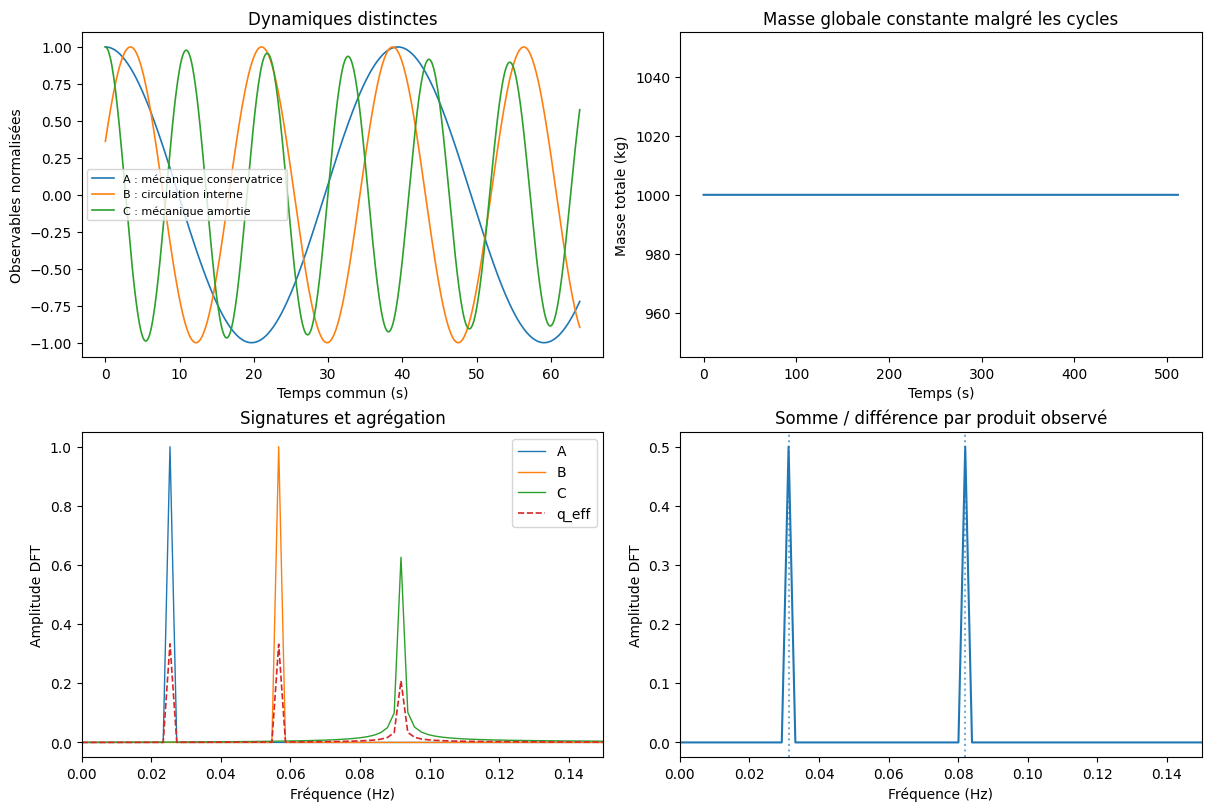

In [9]:
fig,axs=plt.subplots(2,2,figsize=(12,8),layout='constrained')
sl=t<64
axs[0,0].plot(t[sl],qA[sl],label='A : mécanique conservatrice',lw=1.2)
axs[0,0].plot(t[sl],qB[sl],label='B : circulation interne',lw=1.2)
axs[0,0].plot(t[sl],qC[sl],label='C : mécanique amortie',lw=1.2)
axs[0,0].set(xlabel='Temps commun (s)',ylabel='Observables normalisées',title='Dynamiques distinctes');axs[0,0].legend(fontsize=8)
axs[0,1].plot(t, Mtot)
axs[0,1].set(xlabel='Temps (s)',ylabel='Masse totale (kg)',title='Masse globale constante malgré les cycles')
for k in ['A','B','C']:
    axs[1,0].plot(fbins,amplitudes(sources[k]),label=k,lw=1)
axs[1,0].plot(fbins,amplitudes(qeff),label='q_eff',lw=1.2,ls='--')
axs[1,0].set(xlabel='Fréquence (Hz)',ylabel='Amplitude DFT',title='Signatures et agrégation',xlim=(0,0.15));axs[1,0].legend()
axs[1,1].plot(fbins,amplitudes(qcross))
for ff in [f_minus,f_plus]:axs[1,1].axvline(ff,ls=':',alpha=.6)
axs[1,1].set(xlabel='Fréquence (Hz)',ylabel='Amplitude DFT',title='Somme / différence par produit observé',xlim=(0,.15))
plt.show()

## 7 — Verdict et statut des verrous

L'audit est classé **PASS local** uniquement si tous les tests pré-déclarés réussissent. La récupération d'une fréquence imposée par la construction du banc n'est pas une prédiction scientifique indépendante. Les informations de forme (phases, amortissement, flux, masse effective) doivent être suivies par observable; une réduction `M` est insuffisante pour reconstruire `qA,qB,qC`.

**Verrous bloqués :** couplage des secteurs de matière à `S_cand`, solution EOM complète pour cubes hétérogènes, fréquence déterminée sans prescription, dérivation des constantes SI, spectre physique externe indépendant, validation ALMA.

**Étape suivante :** `GVH_CHH_04_Heterogeneous_Aggregation_Benchmark_FAST` — quantifier l'erreur dynamique d'une réduction sous-cubes → état effectif à différents budgets de variables, avec une métrique et des critères préenregistrés; garder l'étude ALMA sur sa branche aveugle indépendante.

In [10]:
LOCKS={
    'S_cand_matter_EOM_derived':False,
    'CHH_closed_effective_dynamics_derived':False,
    'physical_intercube_coupling_calculated':False,
    'universal_internal_activity_variable_derived':False,
    'independent_SI_frequency_predicted':False,
    'ALMA_line_signal_inspected':False,
    'GVH_used_for_ALMA':False,
    'new_GVH_physics_validated':False,
}
all_pass=bool(all(checks.values()))
assert all_pass, [k for k,v in checks.items() if not v]
RESULTS={
 'notebook':NAME,
 'classification':'COMPLEMENTARY_NONCANONICAL_CHH_INTERNAL_FREQUENCY_GATE',
 'local_audit_pass':all_pass,
 'tested_checks':len(checks),
 'checks':{k:bool(v) for k,v in checks.items()},
 'four_levels':{
   'GVH':'HETEROGENEOUS_CUBES_AND_EFFECTIVE_OBSERVABLES_PROPOSED_NOT_S_CAND_DERIVED',
   'established_physics':'OSCILLATOR_DYNAMICS_CIRCULATION_CONTINUITY_DAMPING_AND_DFT',
   'minimal_numeric_test':'THREE_SUBCUBES_SAME_SECONDS_CLOCK_ODE_ANALYTIC_CHECKS_FFT_AND_NONLINEAR_MIXING',
   'scientific_verdict':'LOCAL_CLASSICAL_FREQUENCY_AND_AGGREGATION_QA_PASS__GVH_COUPLING_AND_INDEPENDENT_PREDICTION_BLOCKED'
 },
 'conditions':{
   'synthetic_test':True,'single_SI_clock_seconds':True,'unfitted_frequencies_prescribed':True,
   'T_s':T,'dt_s':DT,'N':N,'frequency_resolution_Hz':1/T,'nyquist_Hz':1/(2*DT),
   'fA_prescribed_Hz':fA,'fB_prescribed_Hz':fB,'fC_prescribed_Hz':fC,
   'gamma_prescribed_per_s':gamma,'J0_prescribed_kg_per_s':J0,'alpha_prescribed':alpha,
   'no_real_solar_system_fit':True,'no_ALMA_signal_inspected':True,
   'ALMA_windows_or_thresholds_unchanged':True,
   'no_GVH_EOM_derived':True,'no_derived_physical_constants':True,
   'total_energy_accounting_for_driven_B_not_defined':True,
   'frozen_weights_equal':True,
 },
 'numeric':{
   'mass_aggregate_kg':float(Mtot[0]),'mass_ptp_kg':float(np.ptp(Mtot)),
   'B_activity_range_kg_per_s':[float(activityB.min()),float(activityB.max())],
   'A_analytic_max_error_m':errA,'C_analytic_max_error_m':errC,
   'C_initial_mechanical_energy_J':float(E_C[0]),'C_final_mechanical_energy_J':float(E_C[-1]),
   'C_accumulated_heat_J':float(Q_C[-1]),
   'C_energy_heat_balance_max_residual_J':float(np.max(np.abs(energy_C_total-energy_C_total[0]))),
   'qeff_peak_frequencies_Hz':{k:float(v[0]) for k,v in peak_matrix['agg'].items()},
   'qeff_peak_amplitudes':{k:float(v[1]) for k,v in peak_matrix['agg'].items()},
   'sidebands_from_nonlinear_observable_Hz':{'difference':float(minus_peak[0]),'sum':float(plus_peak[0])},
   'sideband_peak_amplitudes':{'difference':float(minus_peak[1]),'sum':float(plus_peak[1])},
   'unresolvable_near_mode_delta_Hz':float(fnear-fA)
 },
 'upstream_sources':UPSTREAM_SHA256_FROZEN,
 'source_verification_during_notebook':upstream_audit,
 'scientific_locks':LOCKS,
 'next_step':'GVH_CHH_04_Heterogeneous_Aggregation_Benchmark_FAST'
}
print('CHECKS',len(checks),'PASS',sum(checks.values()))
print('LOCAL_AUDIT_PASS:',all_pass)
print('SCIENTIFIC_VERDICT:',RESULTS['four_levels']['scientific_verdict'])
print(json.dumps(RESULTS['numeric'],indent=2,ensure_ascii=False))
print("GVH_RESULT_JSON_BEGIN"+json.dumps(RESULTS,allow_nan=False,ensure_ascii=False)+"GVH_RESULT_JSON_END")

CHECKS 32 PASS 32
LOCAL_AUDIT_PASS: True
SCIENTIFIC_VERDICT: LOCAL_CLASSICAL_FREQUENCY_AND_AGGREGATION_QA_PASS__GVH_COUPLING_AND_INDEPENDENT_PREDICTION_BLOCKED
{
  "mass_aggregate_kg": 1000.0,
  "mass_ptp_kg": 0.0,
  "B_activity_range_kg_per_s": [
    4.5000000723683025,
    7.499999927631697
  ],
  "A_analytic_max_error_m": 6.85853596138486e-11,
  "C_analytic_max_error_m": 2.4119056751814583e-10,
  "C_initial_mechanical_energy_J": 0.16633972480778805,
  "C_final_mechanical_energy_J": 0.021456630772537736,
  "C_accumulated_heat_J": 0.14488309394534332,
  "C_energy_heat_balance_max_residual_J": 8.990699851274542e-11,
  "qeff_peak_frequencies_Hz": {
    "A": 0.025390625,
    "B": 0.056640625,
    "C": 0.091796875
  },
  "qeff_peak_amplitudes": {
    "A": 0.33339210139930714,
    "B": 0.33201513955584877,
    "C": 0.208661348395116
  },
  "sidebands_from_nonlinear_observable_Hz": {
    "difference": 0.03125,
    "sum": 0.08203125
  },
  "sideband_peak_amplitudes": {
    "difference": 0.49